In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.models import Sequential
import shap

C:\Users\User\anaconda3\envs\TF\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_syn = pd.read_csv("synthetic_train_data_tvae.csv")
df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")
df = pd.concat([df_syn, df_train])

In [3]:
df_syn.columns

Index(['raw_ph', 'raw_ntu', 'initial_cl', 'dosage'], dtype='str')

In [4]:
# X_test = df_test[['raw_ph', 'raw_ntu', 'initial_cl']]
# y_test = df_test['dosage']

# X_syn_train = df_syn_train[['raw_ph', 'raw_ntu', 'initial_cl']]
# y_syn_train = df_syn_train['dosage']

# X_train = df_train[['raw_ph', 'raw_ntu', 'initial_cl']]
# y_train = df_train['dosage']

# X_syn = df_syn[['raw_ph', 'raw_ntu', 'initial_cl']]
# y_syn = df_syn['dosage']

In [5]:
# X_train_val, X_test, y_train_val, y_test = train_test_split(X_syn_train, y_syn_train, test_size=0.2, random_state=42)

In [6]:
# Define Features (X) and Target (y) as specified
feature_cols = ["raw_ph", "raw_ntu", "initial_cl"]
target_col = "dosage"

X = df[feature_cols].values
y = df[target_col].values

In [7]:
# ==============================================================================
# 2. 5-FOLD CROSS-VALIDATION & MODEL EVALUATION LOOP
# ==============================================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Storage containers for fold-wise metrics
metrics_storage = {
    "ANN": {"r2": [], "rmse": [], "mae": []},
    "MLP": {"r2": [], "rmse": [], "mae": []},
}

# Storage for final fold predictions (useful for residual plotting)
last_y_test, last_y_pred_ann, last_y_pred_mlp, last_X_test = None, None, None, None

print("Executing 5-Fold Cross-Validation for ANN and MLP...")

for fold, (train_index, test_index) in enumerate(kf.split(X, y)):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Feature Scaling (Fit on training fold, transform both to prevent data leakage)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # --- Model A: TensorFlow/Keras ANN ---
    tf.random.set_seed(42 + fold)
    ann_model = Sequential(
        [
            Dense(64, activation="relu", input_shape=(X_train_scaled.shape[1],)),
            Dense(32, activation="relu"),
            Dense(16, activation="relu"),
            Dense(1, activation="linear"),
        ]
    )
    ann_model.compile(optimizer="adam", loss="mean_squared_error")
    early_stop = EarlyStopping(
        monitor="loss", patience=15, restore_best_weights=True
    )
    ann_model.fit(
        X_train_scaled,
        y_train,
        epochs=100,
        batch_size=8,
        callbacks=[early_stop],
        verbose=0,
    )
    y_pred_ann = ann_model.predict(X_test_scaled, verbose=0).flatten()

    metrics_storage["ANN"]["r2"].append(r2_score(y_test, y_pred_ann))
    metrics_storage["ANN"]["rmse"].append(
        np.sqrt(mean_squared_error(y_test, y_pred_ann))
    )
    metrics_storage["ANN"]["mae"].append(
        mean_absolute_error(y_test, y_pred_ann)
    )

    # --- Model B: Scikit-Learn MLPRegressor ---
    mlp_model = MLPRegressor(
        hidden_layer_sizes=(64, 32, 16),
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=42 + fold,
    )
    mlp_model.fit(X_train_scaled, y_train)
    y_pred_mlp = mlp_model.predict(X_test_scaled)

    metrics_storage["MLP"]["r2"].append(r2_score(y_test, y_pred_mlp))
    metrics_storage["MLP"]["rmse"].append(
        np.sqrt(mean_squared_error(y_test, y_pred_mlp))
    )
    metrics_storage["MLP"]["mae"].append(
        mean_absolute_error(y_test, y_pred_mlp)
    )

    # Save last fold variables for visualization
    if fold == 4:
        last_y_test, last_y_pred_ann, last_y_pred_mlp, last_X_test = (
            y_test,
            y_pred_ann,
            y_pred_mlp,
            X_test_scaled,
        )

C:\Users\User\anaconda3\envs\TF\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Executing 5-Fold Cross-Validation for ANN and MLP...


C:\Users\User\anaconda3\envs\TF\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
C:\Users\User\anaconda3\envs\TF\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


C:\Users\User\anaconda3\envs\TF\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


C:\Users\User\anaconda3\envs\TF\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



CROSS-VALIDATION PERFORMANCE SUMMARY
           Model   Mean R2   Std R2  Mean RMSE  Std RMSE  Mean MAE  Std MAE
  TensorFlow ANN -0.051905 0.024958   4.503791  0.095257  3.636599 0.150507
Scikit-Learn MLP -0.041206 0.029230   4.483420  0.185537  3.615699 0.188072


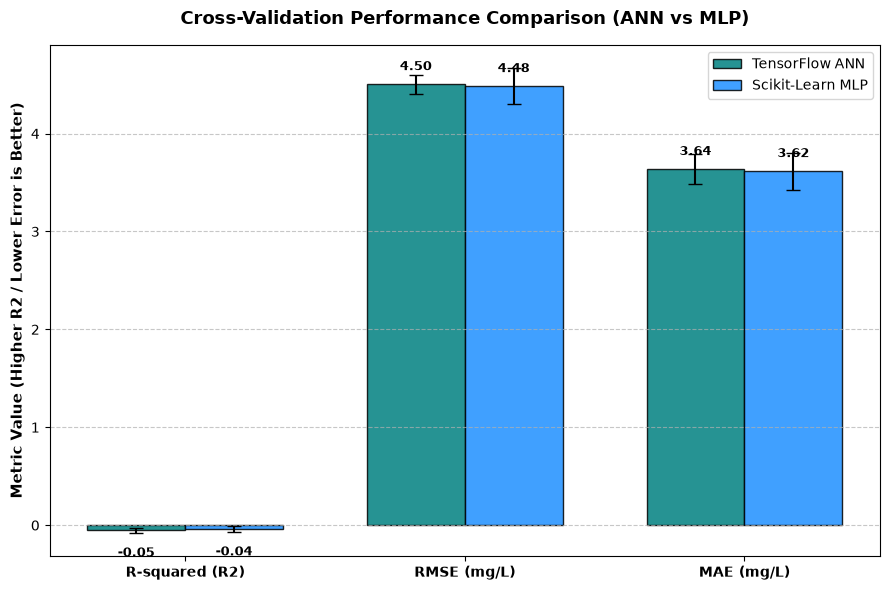

In [8]:
# ==============================================================================
# 3. METRIC AGGREGATION & SUMMARY TABLE
# ==============================================================================
summary_df = pd.DataFrame(
    {
        "Model": ["TensorFlow ANN", "Scikit-Learn MLP"],
        "Mean R2": [
            np.mean(metrics_storage["ANN"]["r2"]),
            np.mean(metrics_storage["MLP"]["r2"]),
        ],
        "Std R2": [
            np.std(metrics_storage["ANN"]["r2"]),
            np.std(metrics_storage["MLP"]["r2"]),
        ],
        "Mean RMSE": [
            np.mean(metrics_storage["ANN"]["rmse"]),
            np.mean(metrics_storage["MLP"]["rmse"]),
        ],
        "Std RMSE": [
            np.std(metrics_storage["ANN"]["rmse"]),
            np.std(metrics_storage["MLP"]["rmse"]),
        ],
        "Mean MAE": [
            np.mean(metrics_storage["ANN"]["mae"]),
            np.mean(metrics_storage["MLP"]["mae"]),
        ],
        "Std MAE": [
            np.std(metrics_storage["ANN"]["mae"]),
            np.std(metrics_storage["MLP"]["mae"]),
        ],
    }
)

print("\n" + "=" * 65)
print("CROSS-VALIDATION PERFORMANCE SUMMARY")
print("=" * 65)
print(summary_df.to_string(index=False))
print("=" * 65)

# ==============================================================================
# 4. VISUALIZATION A: PERFORMANCE METRIC COMPARISON (VERTICAL BAR CHART + ERROR BARS)
# ==============================================================================
metrics_list = ["R-squared (R2)", "RMSE (mg/L)", "MAE (mg/L)"]
ann_means = [
    summary_df.loc[0, "Mean R2"],
    summary_df.loc[0, "Mean RMSE"],
    summary_df.loc[0, "Mean MAE"],
]
ann_stds = [
    summary_df.loc[0, "Std R2"],
    summary_df.loc[0, "Std RMSE"],
    summary_df.loc[0, "Std MAE"],
]
mlp_means = [
    summary_df.loc[1, "Mean R2"],
    summary_df.loc[1, "Mean RMSE"],
    summary_df.loc[1, "Mean MAE"],
]
mlp_stds = [
    summary_df.loc[1, "Std R2"],
    summary_df.loc[1, "Std RMSE"],
    summary_df.loc[1, "Std MAE"],
]

fig, ax = plt.subplots(figsize=(9, 6))
x = np.arange(len(metrics_list))
width = 0.35

rects1 = ax.bar(
    x - width / 2,
    ann_means,
    width,
    yerr=ann_stds,
    label="TensorFlow ANN",
    color="teal",
    edgecolor="k",
    capsize=5,
    alpha=0.85,
)
rects2 = ax.bar(
    x + width / 2,
    mlp_means,
    width,
    yerr=mlp_stds,
    label="Scikit-Learn MLP",
    color="dodgerblue",
    edgecolor="k",
    capsize=5,
    alpha=0.85,
)

ax.set_ylabel(
    "Metric Value (Higher R2 / Lower Error is Better)",
    fontsize=11,
    fontweight="bold",
)
ax.set_title(
    "Cross-Validation Performance Comparison (ANN vs MLP)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xticks(x)
ax.set_xticklabels(metrics_list, fontsize=10, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.7)


def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        va_pos = "bottom" if height >= 0 else "top"
        ax.annotate(
            f"{height:.2f}",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 8 if height >= 0 else -12),
            textcoords="offset points",
            ha="center",
            va=va_pos,
            fontsize=9,
            fontweight="bold",
        )


autolabel(rects1)
autolabel(rects2)
plt.tight_layout()
plt.show()

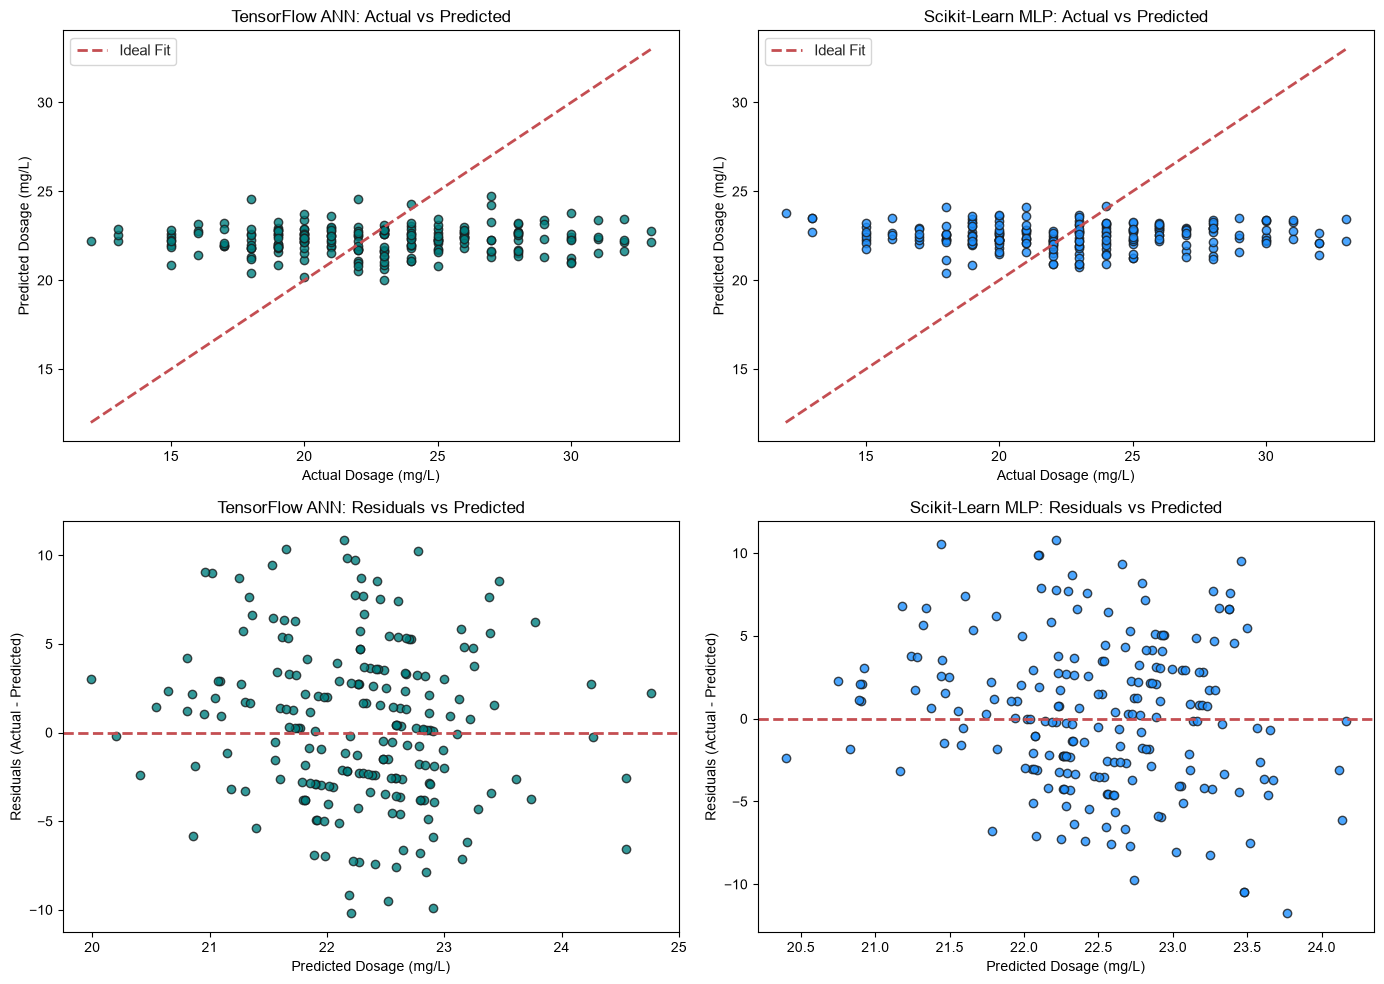

In [9]:
# ==============================================================================
# 5. VISUALIZATION B: PARITY & RESIDUAL DIAGNOSTICS
# ==============================================================================
residuals_ann = last_y_test - last_y_pred_ann
residuals_mlp = last_y_test - last_y_pred_mlp

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.set_theme(style="whitegrid")

# Parity Plots
for i, (y_pred, name, color) in enumerate(
    zip(
        [last_y_pred_ann, last_y_pred_mlp],
        ["TensorFlow ANN", "Scikit-Learn MLP"],
        ["teal", "dodgerblue"],
    )
):
    axes[0, i].scatter(
        last_y_test, y_pred, color=color, alpha=0.8, edgecolor="k"
    )
    axes[0, i].plot(
        [last_y_test.min(), last_y_test.max()],
        [last_y_test.min(), last_y_test.max()],
        "r--",
        lw=2,
        label="Ideal Fit",
    )
    axes[0, i].set_title(f"{name}: Actual vs Predicted")
    axes[0, i].set_xlabel("Actual Dosage (mg/L)")
    axes[0, i].set_ylabel("Predicted Dosage (mg/L)")
    axes[0, i].legend()

# Residual Plots
for i, (residuals, y_pred, name, color) in enumerate(
    zip(
        [residuals_ann, residuals_mlp],
        [last_y_pred_ann, last_y_pred_mlp],
        ["TensorFlow ANN", "Scikit-Learn MLP"],
        ["teal", "dodgerblue"],
    )
):
    axes[1, i].scatter(
        y_pred, residuals, color=color, alpha=0.8, edgecolor="k"
    )
    axes[1, i].axhline(y=0, color="r", linestyle="--", lw=2)
    axes[1, i].set_title(f"{name}: Residuals vs Predicted")
    axes[1, i].set_xlabel("Predicted Dosage (mg/L)")
    axes[1, i].set_ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()


Computing SHAP values...


100%|██████████| 208/208 [00:01<00:00, 198.99it/s]


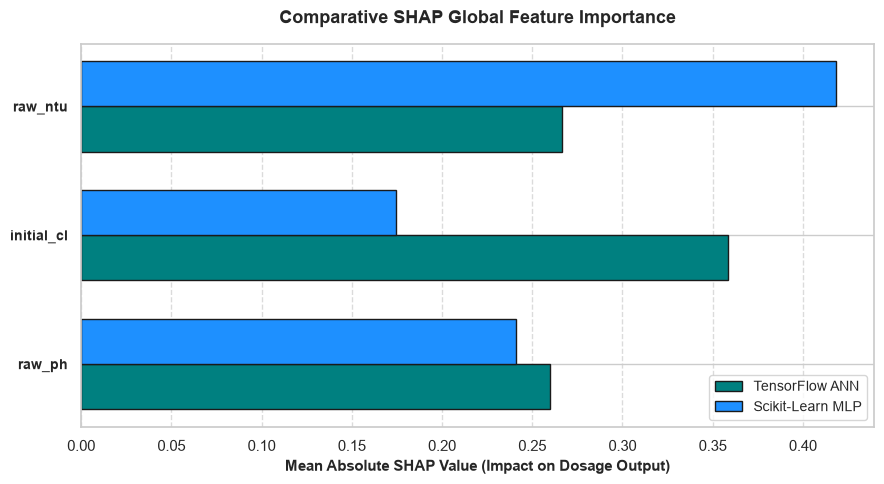

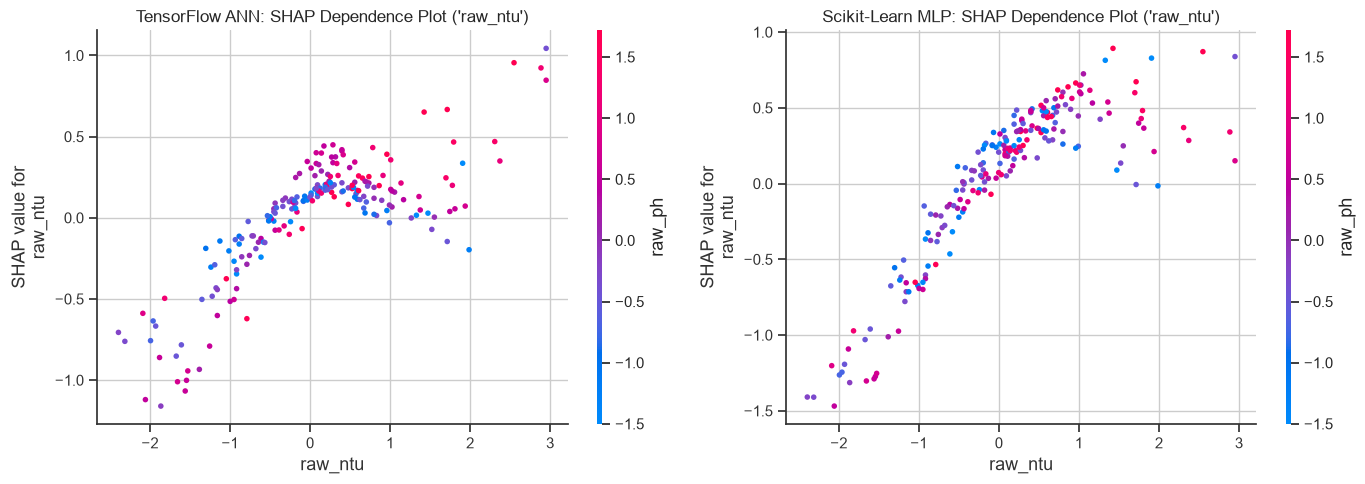

In [10]:
# ==============================================================================
# 6. VISUALIZATION C: SHAP FEATURE IMPORTANCE & DEPENDENCE PLOTS
# ==============================================================================
print("Computing SHAP values...")
background_data = shap.kmeans(X_train_scaled, 15)


def ann_predict_wrapper(data_array):
    return ann_model.predict(data_array, verbose=0).flatten()


explainer_ann = shap.KernelExplainer(ann_predict_wrapper, background_data)
shap_values_ann = explainer_ann.shap_values(last_X_test)

explainer_mlp = shap.KernelExplainer(mlp_model.predict, background_data)
shap_values_mlp = explainer_mlp.shap_values(last_X_test)

# --- C1. Side-by-Side Global Bar Chart ---
mean_abs_ann = np.mean(np.abs(shap_values_ann), axis=0)
mean_abs_mlp = np.mean(np.abs(shap_values_mlp), axis=0)

shap_df = pd.DataFrame(
    {
        "Feature": feature_cols,
        "TensorFlow ANN": mean_abs_ann,
        "Scikit-Learn MLP": mean_abs_mlp,
    }
)
shap_df["Average"] = (shap_df["TensorFlow ANN"] + shap_df["Scikit-Learn MLP"]) / 2
shap_df = shap_df.sort_values(by="Average", ascending=True).drop(
    columns=["Average"]
)

fig, ax = plt.subplots(figsize=(9, 5))
x_pos = np.arange(len(shap_df["Feature"]))
bar_width = 0.35

ax.barh(
    x_pos - bar_width / 2,
    shap_df["TensorFlow ANN"],
    bar_width,
    label="TensorFlow ANN",
    color="teal",
    edgecolor="k",
)
ax.barh(
    x_pos + bar_width / 2,
    shap_df["Scikit-Learn MLP"],
    bar_width,
    label="Scikit-Learn MLP",
    color="dodgerblue",
    edgecolor="k",
)

ax.set_xlabel(
    "Mean Absolute SHAP Value (Impact on Dosage Output)",
    fontsize=11,
    fontweight="bold",
)
ax.set_title(
    "Comparative SHAP Global Feature Importance",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_yticks(x_pos)
ax.set_yticklabels(shap_df["Feature"], fontsize=10, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# --- C2. SHAP Dependence Plots ---
# Creates dependence plots for the primary feature 'raw_ntu' (index 1 in feature_cols)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# TensorFlow ANN Dependence Plot
plt.sca(axes[0])
shap.dependence_plot(
    "raw_ntu",
    shap_values_ann,
    pd.DataFrame(last_X_test, columns=feature_cols),
    display_features=pd.DataFrame(last_X_test, columns=feature_cols),
    ax=axes[0],
    show=False,
)
axes[0].set_title("TensorFlow ANN: SHAP Dependence Plot ('raw_ntu')")

# Scikit-Learn MLP Dependence Plot
plt.sca(axes[1])
shap.dependence_plot(
    "raw_ntu",
    shap_values_mlp,
    pd.DataFrame(last_X_test, columns=feature_cols),
    display_features=pd.DataFrame(last_X_test, columns=feature_cols),
    ax=axes[1],
    show=False,
)
axes[1].set_title("Scikit-Learn MLP: SHAP Dependence Plot ('raw_ntu')")

plt.tight_layout()
plt.show()

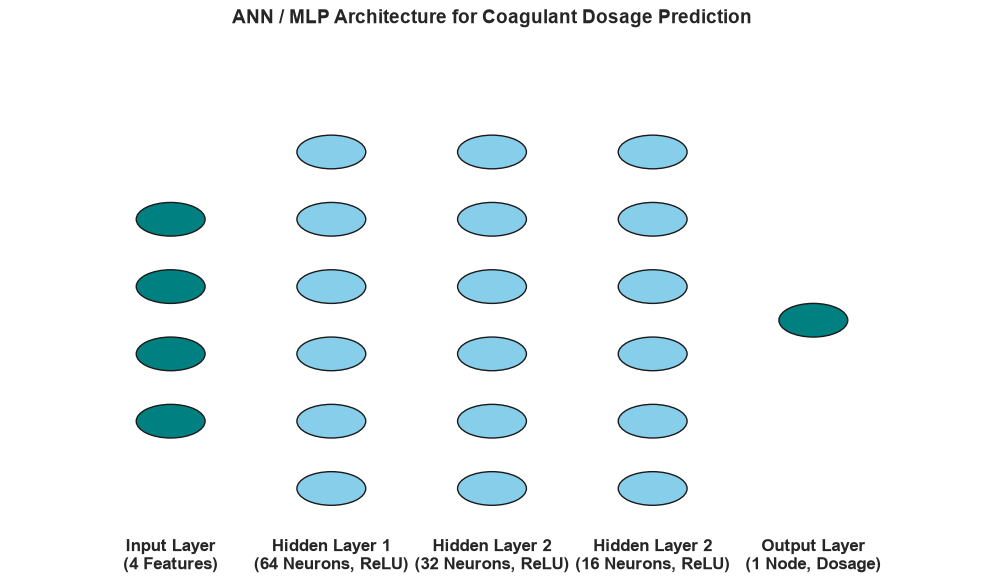

In [11]:
import matplotlib.pyplot as plt
import numpy as np


def draw_neural_net(ax, layer_sizes, layer_names):
    """Draws a neural network architecture diagram using matplotlib.

    - ax: matplotlib axis
    - layer_sizes: list of integer sizes for each layer (e.g., [4, 64, 32, 1])
    - layer_names: list of names for each layer
    """
    v_spacing = 1.0 / float(max(layer_sizes) + 1)
    h_spacing = 1.0 / float(len(layer_sizes) + 1)

    # Draw nodes
    for n, layer_size in enumerate(layer_sizes):
        layer_top = v_spacing * (layer_size - 1) / 2.0 + (1 - v_spacing) / 2.0
        for m in range(layer_size):
            # Limit the number of drawn nodes for large layers to keep the visual clean
            if layer_size > 10 and 2 < m < layer_size - 2:
                if m == 3:  # Draw ellipsis dots for hidden nodes
                    ax.text(
                        (n + 1) * h_spacing,
                        layer_top - m * v_spacing,
                        "...",
                        fontsize=20,
                        ha="center",
                        va="center",
                        rotation=90,
                    )
                continue

            circle = plt.Circle(
                (
                    (n + 1) * h_spacing,
                    layer_top - m * v_spacing if layer_size <= 10 else (
                        layer_top - (m if m < 3 else layer_size - 1) * v_spacing
                    ),
                ),
                v_spacing / 4.0,
                color="teal" if n == 0 or n == len(layer_sizes) - 1 else "skyblue",
                ec="k",
                zorder=4,
            )
            ax.add_artist(circle)

        # Add Layer Labels
        ax.text(
            (n + 1) * h_spacing,
            -0.1,
            layer_names[n],
            fontsize=12,
            fontweight="bold",
            ha="center",
        )


# Initialize Figure
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis("off")

# Define Architecture Layers matching your models:
# Input (4 features) -> Hidden 1 (64 -> displayed as 6 nodes + ellipsis) -> Hidden 2 (32 -> displayed as 6 nodes + ellipsis) -> Output (1 node)
layer_sizes = [4, 6, 6, 6, 1]
layer_names = [
    "Input Layer\n(4 Features)",
    "Hidden Layer 1\n(64 Neurons, ReLU)",
    "Hidden Layer 2\n(32 Neurons, ReLU)",
    "Hidden Layer 2\n(16 Neurons, ReLU)",
    "Output Layer\n(1 Node, Dosage)",
]

draw_neural_net(ax, layer_sizes, layer_names)

plt.title(
    "ANN / MLP Architecture for Coagulant Dosage Prediction",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.tight_layout()
plt.show()

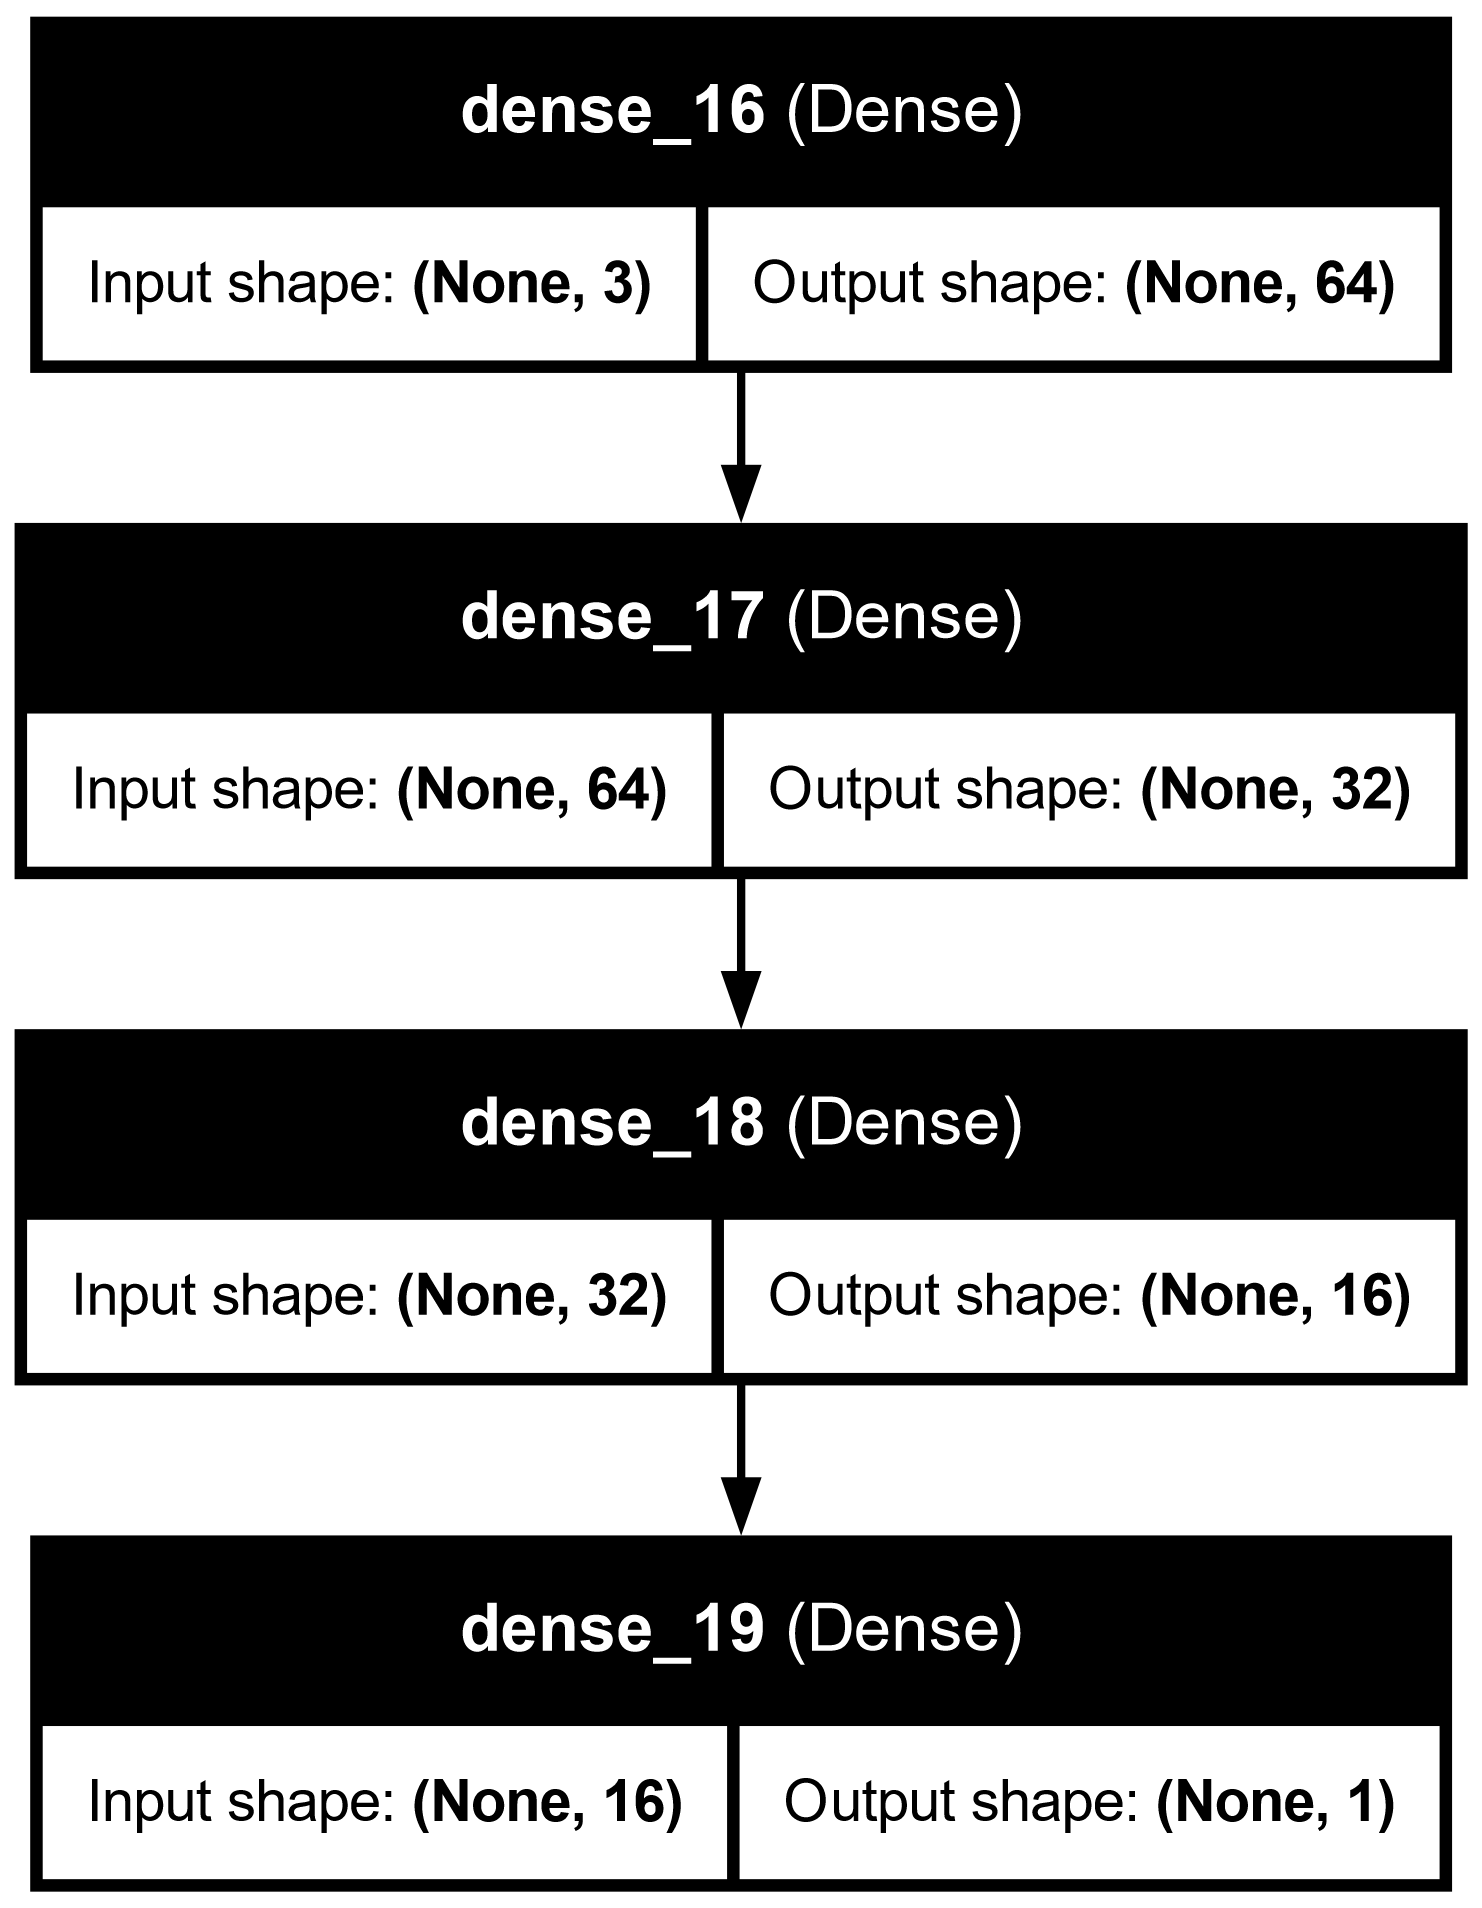

In [12]:
from tensorflow.keras.utils import plot_model

# Generates and saves an image file named 'ann_architecture.png'
plot_model(
    ann_model,
    to_file="ann_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    rankdir="TB",  # Top-to-bottom layout ('LR' for left-to-right)
    expand_nested=False,
    dpi=300,
)